# Train, Validation, and Test Split

How the data is divided into the final test set, which is used once at the end, and the cross validation folds on the training set, which later stages use to compare and tune models.

**How to use this notebook.** The cells marked *Decision* hold the data, the target, and the split settings. Edit them, then choose Run All. The checks below show whether the split is sound, and the last cells save the sets as parquet files and write the `split` section of `ml_spec.yaml`. Raw rows are never shown here.

## Setup

Finds the project root, loads the shared spec `ml_spec.yaml`, and checks the kernel. Run this cell first.

In [1]:
import os
import sys
from pathlib import Path

# The project root is the closest folder with ml_spec.yaml. Everything runs from there.
here = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in here if (p / "ml_spec.yaml").is_file()), Path.cwd())
os.chdir(ROOT)
# The project's own code (src) comes from this folder, also in an experiment's worktree, where the editable
# install in .venv would point to the main project.
sys.path.insert(0, str(ROOT))

# Shared code from the ML project skills
sys.path.insert(0, r"/Users/ani/.claude/skills/ml-train-test-split/scripts")
import ml_common
import nb_common
try:  # MLflow tracking, in the ML project skills: keeps a copy of each chart for the stage's run
    import tracking
    tracking.capture_figures()
except ImportError:
    tracking = None

SPEC_PATH = str(ROOT / "ml_spec.yaml")
spec = ml_common.migrate(ml_common.load(SPEC_PATH)) if os.path.exists(SPEC_PATH) else ml_common.template()
PATHS = ml_common.project_paths(spec, str(ROOT))
NOTEBOOK = os.path.join(PATHS["notebooks"], "05_split.ipynb")
STAGE = "split"

print("Project root:", ROOT)
print("Python:", sys.executable)
if (ROOT / ".venv").is_dir() and Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    print("Warning: this kernel is not the project's .venv. Choose 'Select Kernel' and pick the project kernel.")

Project root: /Users/ani/Projects/16_weather_prediction
Python: /Users/ani/Projects/16_weather_prediction/.venv/bin/python


In [2]:
import datetime as dt

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import split_core
from nb_common import load_table as load_data

## What This Builds On

* **Task:** forecasting. **Target:** `temperature_2m_max`, The city's maximum air temperature at 2 m (degrees Celsius) on the target date, its local calendar day.
* **Unit of prediction:** One city on one target date (the city's next local day, seen from a request). **Entity:** `city`
* **Prediction time:** Whenever a request arrives during the day before the target date. The current day is incomplete, so inputs stop at the last complete day, two days before the target date., column `date`, horizon 2 days
* **Outcome window:** The single target day, two days after the last day the inputs may use. **Label delay:** 1 day (known once the target day is complete and in the archive)
* **From the EDA:** grain `date` + `city`, 0 exact duplicate rows

The cell below prints the same from the spec, and whether modelling may start (the framing is confirmed and the targeted EDA has run).

In [3]:
framing = spec.get("framing") or {}
target_spec = framing.get("target") or {}
print(f"task: {framing.get('task_type')}, target: {target_spec.get('name')}, entity: {framing.get('entity_id_cols')}")
print(f"prediction time: {(framing.get('prediction_time') or {}).get('column')}, outcome window: "
      f"{target_spec.get('outcome_window')}, label delay: {target_spec.get('label_delay')}")
blockers = ml_common.modelling_blockers(spec)
print("Modelling may start." if not blockers else "Not ready for modelling: " + "; ".join(blockers))

task: forecasting, target: temperature_2m_max, entity: ['city']
prediction time: date, outcome window: The single target day, two days after the last day the inputs may use, label delay: 1 day (known once the target day is complete and in the archive)
Modelling may start.


## Data and Target

*`build_target` builds the target when it is not a column yet, following `framing.target.construction`. It must only use information known at the outcome, and it runs before the split, so every set gets the same rule.*

In [4]:
# Decision
DATA_PATH = 'data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv'
TARGET = 'temperature_2m_max'
TASK_TYPE = 'forecasting'


def build_target(df):
    """The target is a column in the data, so nothing is built here."""
    return df

In [5]:
df = build_target(load_data(DATA_PATH))
print(f"{DATA_PATH}: {len(df):,} rows and {df.shape[1]} columns")
assert TARGET in df.columns, f"The target {TARGET!r} is not in the data. Fill in build_target above."

data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv: 50,250 rows and 23 columns


## Split Settings

The latest period is the test set, as in production, where the model predicts the future from the past. Cross validation uses rolling backtest folds: each fold trains on the data before its validation window, with the same gap, and the windows move forward in time.

The model forecasts the future, so the test set is the latest period and CV uses backtest folds that move forward in time. A random split would let the model learn from days after the ones it is scored on. Every city has every date, so each period and fold holds all 50 cities equally, which is the stratification by city the user asked for.

The suggested 2 day test period would hold only 100 forecasts, and one hot spell would swing the score. Each test day is its own 2 day ahead forecast, so the test period can be long: 182 days (2026-04-03 to 2026-10-01) covers spring and summer in the north and autumn and winter in the south, with 9,100 forecasts, and leaves about 822 days for training. No gap is needed, because feature engineering only uses lags of at least 2 days.

Four expanding folds of 91 days cover the last year before the test, so every season is scored once in CV. The first fold trains on about 458 days, and later folds keep all earlier data for the seasonal features.

There are no duplicate rows; keep_together is the default and changes nothing.

*Settings:* `strategy` is `random`, `group`, or `time`. `test_size` is the share held out for the random and group strategies. `test_days` is the length of the test period, and `gap_days` the days left out before it (and before each validation window), for the time strategy. `stratify` keeps the class balance equal across sets. `group_col` keeps every row of an entity on one side (group), or is used to report overlap (time). `cv` sets the folds: `n_folds`, and for time `valid_days` (length of each validation window), `window` (`expanding` uses all earlier data, `sliding` only the last `train_days`). `duplicates` is `keep_together`, `drop`, or `ignore`. `missing_target` is `drop` or `error`.

In [6]:
# Decision
SPLIT = {
    'strategy': 'time',
    'test_days': 182,
    'gap_days': 0,
    'group_col': 'city',
    'date_col': 'date',
    'cv': {'n_folds': 4, 'window': 'expanding', 'valid_days': 91, 'train_days': None},
    'duplicates': 'keep_together',
    'missing_target': 'drop',
    'seed': 42,
}

## Prepare the Data

Adds a `row_id` column (the row's position in the original file, so every row can be traced back), drops rows without a target, and finds exact duplicate rows.

In [7]:
SPLIT = split_core.settings(SPLIT)
data, prep, duplicate_key = split_core.prepare(df, TARGET, SPLIT)
print(f"Rows in: {prep['rows_in']:,}. Rows without a target: {prep['missing_target']:,} (dropped).")
print(f"Exact duplicate rows: {prep['duplicate_rows']:,}. Handling: {SPLIT['duplicates']}"
      + (f", {prep['duplicates_dropped']:,} dropped" if prep["duplicates_dropped"] else ""))
print(f"Rows to split: {prep['rows_out']:,}")

Rows in: 50,250. Rows without a target: 0 (dropped).
Exact duplicate rows: 0. Handling: keep_together
Rows to split: 50,250


## Make the Split

In [8]:
result = split_core.make_split(data, TARGET, TASK_TYPE, SPLIT, duplicate_key)
train, test, gap, folds = result["train"], result["test"], result["gap"], result["folds"]
print(f"Strategy: {SPLIT['strategy']}. CV method: {result['cv_method']}, {len(folds)} folds.")
print(f"Train: {len(train):,} rows. Test: {len(test):,} rows." + (f" Gap: {len(gap):,} rows." if len(gap) else ""))
if result["info"].get("unreadable_dates"):
    print(f"Rows dropped because the date could not be read: {result['info']['unreadable_dates']:,}")

Strategy: time. CV method: time_backtest, 4 folds.
Train: 41,150 rows. Test: 9,100 rows.


## Checks

### Size and Balance of Each Set

Every set should have the same class balance (or a similar target mean). For a time split, the dates show the order of the sets.

In [9]:
classification = split_core.is_classification(TASK_TYPE, data[TARGET])
date_col = SPLIT.get("date_col")
parts = {"train": train, "gap": gap, "test": test} if len(gap) else {"train": train, "test": test}
rows = []
for name, part in parts.items():
    row = {"set": name, "rows": len(part), "share": round(len(part) / len(data), 4)}
    if classification:
        row.update({f"share of {k}": v for k, v in part[TARGET].value_counts(normalize=True).round(4).items()})
    else:
        row.update({"target mean": round(part[TARGET].mean(), 4), "target std": round(part[TARGET].std(), 4)})
    if date_col and date_col in part:
        d = pd.to_datetime(part[date_col], errors="coerce", format="mixed")
        row.update({"first date": f"{d.min():%Y-%m-%d}", "last date": f"{d.max():%Y-%m-%d}"})
    rows.append(row)
display(pd.DataFrame(rows))

,set,rows,share,target mean,target std,first date,last date
0,train,41150,0.8189,22.0325,10.1589,2024-01-01,2026-04-02
1,test,9100,0.1811,26.2768,7.9875,2026-04-03,2026-10-01


### Cross Validation Folds

Each fold validates on its own rows and trains on the rest of the training set. For a time split, a fold trains only on dates before its validation window.

In [10]:
display(folds)

,fold,n_train,n_valid,train_start,train_end,valid_start,valid_end
0,0,22950,4550,2024-01-01,2025-04-03,2025-04-04,2025-07-03
1,1,27500,4550,2024-01-01,2025-07-03,2025-07-04,2025-10-02
2,2,32050,4550,2024-01-01,2025-10-02,2025-10-03,2026-01-01
3,3,36600,4550,2024-01-01,2026-01-01,2026-01-02,2026-04-02


### Timeline

For a time split: what each fold trains and validates on, and the final split. Grey is training, blue is validation or test, and the white space between them is the gap.

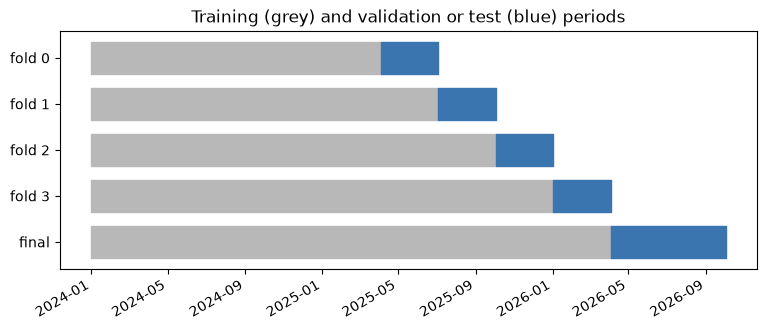

In [11]:
if SPLIT["strategy"] == "time":
    import matplotlib.dates as mdates
    span = lambda a, b: (mdates.date2num(pd.Timestamp(a)), (pd.Timestamp(b) - pd.Timestamp(a)).days + 1)
    train_dates = pd.to_datetime(train[date_col], format="mixed")
    test_dates = pd.to_datetime(test[date_col], format="mixed")
    bars = [(f"fold {int(f.fold)}", span(f.train_start, f.train_end), span(f.valid_start, f.valid_end)) for f in folds.itertuples()]
    bars.append(("final", span(train_dates.min(), train_dates.max()), span(test_dates.min(), test_dates.max())))
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(bars) + 1))
    for i, (label, tr, va) in enumerate(bars):
        ax.broken_barh([tr], (i - 0.35, 0.7), color="#b8b8b8")
        ax.broken_barh([va], (i - 0.35, 0.7), color="#3b75af")
    ax.set_yticks(range(len(bars)), [b[0] for b in bars])
    ax.invert_yaxis()
    ax.xaxis_date()
    ax.set_title("Training (grey) and validation or test (blue) periods")
    fig.autofmt_xdate()
    plt.show()
else:
    print("Not a time split, so there is no timeline. Folds are drawn at random" + (" by group." if SPLIT["strategy"] == "group" else "."))

### Leakage Checks

1. No test row should have an exact copy in training.
2. For a group split, no entity may be on both sides. For a time split, the same entities appear before and after the cutoff, which is expected.
3. For a time split, the gap between training and test, and inside every fold, must be at least `gap_days`.

In [12]:
problems = []
content_cols = [c for c in train.columns if c not in (prep["row_id_col"], split_core.FOLD)]
train_hashes = set(pd.util.hash_pandas_object(train[content_cols], index=False))
copies = int(pd.util.hash_pandas_object(test[content_cols], index=False).isin(train_hashes).sum())
print(f"1. Test rows with an exact copy in training: {copies:,}")
if copies:
    problems.append(f"{copies:,} test rows have an exact copy in training.")

entity = SPLIT.get("group_col")
if entity and entity in train:
    both = set(train[entity].dropna()) & set(test[entity].dropna())
    print(f"2. Values of {entity} in both training and test: {len(both):,} of {test[entity].nunique():,} in test")
    if SPLIT["strategy"] == "group" and both:
        problems.append(f"{len(both):,} values of {entity} are in both training and test.")
else:
    print("2. No entity column set, so entity overlap was not checked.")

if SPLIT["strategy"] == "time":
    gap_days = float(SPLIT["gap_days"] or 0)
    actual = (pd.to_datetime(test[date_col], format="mixed").min() - pd.to_datetime(train[date_col], format="mixed").max()).days
    print(f"3. Days between the last training date and the first test date: {actual} (gap_days: {gap_days:g})")
    if actual < gap_days:
        problems.append(f"The gap before the test set is {actual} days, less than gap_days.")
    for f in folds.itertuples():
        g = (pd.Timestamp(f.valid_start) - pd.Timestamp(f.train_end)).days
        if g < gap_days:
            problems.append(f"Fold {f.fold}: the gap is {g} days, less than gap_days.")
else:
    print("3. Not a time split, so there is no gap to check.")

print()
print("Problems: " + (" ".join(problems) if problems else "none found."))

1. Test rows with an exact copy in training: 0
2. Values of city in both training and test: 50 of 50 in test
3. Days between the last training date and the first test date: 1 (gap_days: 0)

Problems: none found.


## Save the Sets

Every file is parquet, in the processed data folder. `train.parquet` keeps a `fold` column: the CV fold the row validates, or -1. Later stages read the folds with `split_core.cv_splits(train, spec['split'])`.

In [13]:
files, text_cols = split_core.save(result, PATHS["data_processed"])
for name, path in files.items():
    print(f"{name}: {ml_common.relpath(path, str(ROOT))} ({os.path.getsize(path) / 1e6:.1f} MB)")
if text_cols:
    print("Columns that mix types were saved as text: " + ", ".join(text_cols))

train: data/processed/train.parquet (1.1 MB)
test: data/processed/test.parquet (0.3 MB)
folds: data/processed/cv_folds.parquet (0.0 MB)


## Risks, Assumptions, Open Questions, and Decisions

`resolved_questions` closes open questions in the spec that this split answers, by ID.

In [14]:
# Decision
risks = [
    {
        'problem': 'The suggested test period and CV windows were 2 days long, far too few forecasts for a stable score.',
        'resolution': 'A 182 day test period and four 91 day CV windows.',
    },
    {
        'problem': 'The test period covers only half a year, so the test score says nothing about northern winter.',
        'resolution': 'Accepted; CV covers every season, and the evaluation can slice the test by month and hemisphere.',
    },
]

assumptions = ['The weather of April to September 2026 is like the weather the system will forecast next.']

open_questions = []

decisions = [
    {
        'decision': 'Time split with a 182 day test period (2026-04-03 to 2026-10-01), no gap, and four expanding 91 day CV folds.',
        'reason': 'The model forecasts the future; the 2 day horizon is enforced by the feature lags, and longer windows give stable scores.',
    },
]

resolved_questions = [
    {
        'id': 'Q2',
        'answer': 'The test period is 182 days (2026-04-03 to 2026-10-01); CV covers the year before it in four 91 day folds.',
    },
]

## Write to the Spec

Replaces the `split` section of `ml_spec.yaml` with this run, and records the run.

In [15]:
dates = lambda part: pd.to_datetime(part[date_col], format="mixed") if date_col and len(part) else None
split_section = split_core.plain({
    "strategy": SPLIT["strategy"],
    "data_source": DATA_PATH,
    "target": TARGET,
    "task_type": TASK_TYPE,
    "row_id_col": prep["row_id_col"],
    "date_col": date_col,
    "group_col": SPLIT.get("group_col"),
    "stratify": bool(SPLIT.get("stratify")) and classification and SPLIT["strategy"] != "time",
    "seed": SPLIT.get("seed"),
    "test": {
        "rows": len(test),
        "share": round(len(test) / len(data), 4),
        "size": SPLIT.get("test_size") if SPLIT["strategy"] != "time" else None,
        "days": SPLIT.get("test_days") if SPLIT["strategy"] == "time" else None,
        "start": dates(test).min() if SPLIT["strategy"] == "time" else None,
        "end": dates(test).max() if SPLIT["strategy"] == "time" else None,
    },
    "gap_days": SPLIT.get("gap_days") if SPLIT["strategy"] == "time" else None,
    "cv": {
        "method": result["cv_method"],
        "n_folds": len(folds),
        "window": SPLIT["cv"].get("window") if SPLIT["strategy"] == "time" else None,
        "valid_days": (SPLIT["cv"].get("valid_days") or SPLIT.get("test_days")) if SPLIT["strategy"] == "time" else None,
        "train_days": SPLIT["cv"].get("train_days") if SPLIT["strategy"] == "time" else None,
        "folds": folds.to_dict("records"),
    },
    "duplicates": {"handling": SPLIT["duplicates"], "rows": prep["duplicate_rows"], "dropped": prep["duplicates_dropped"]},
    "dropped": {"missing_target": prep["missing_target"], "unreadable_dates": result["info"].get("unreadable_dates", 0)},
    "rows": {"train": len(train), "test": len(test), "gap": len(gap)},
    "files": {k: ml_common.relpath(p, str(ROOT)) for k, p in files.items()},
    "checks": {"problems": problems, "test_rows_with_copy_in_train": copies},
    "run_at": dt.datetime.now().replace(microsecond=0).isoformat(),
})
nb_common.write_stage(SPEC_PATH, "split", split_section, "ml-train-test-split", assumptions, open_questions, decisions,
                      replace=True)
not_found = nb_common.resolve_questions(SPEC_PATH, resolved_questions, "ml-train-test-split")
if not_found:
    print("These open question IDs were not found: " + ", ".join(map(str, not_found)))
nb_common.record_run(SPEC_PATH, STAGE, NOTEBOOK, "ml-train-test-split")
print("Wrote the split section of ml_spec.yaml." + (" Problems: " + " ".join(problems) if problems else ""))

Wrote the split section of ml_spec.yaml.


## Log to MLflow

Logs this run to the project's experiment on the shared MLflow server: the settings, the metrics, the tables, and the charts above, read from what this notebook just wrote to the spec. The run is marked as the current one for this stage. When the server is not reachable, nothing is logged and the notebook still finishes.

In [16]:
MLFLOW_RUN = tracking.log_stage(SPEC_PATH, STAGE, NOTEBOOK, "ml-train-test-split") if tracking else None

MLflow: logged the split run to ml/16-weather-prediction: http://127.0.0.1:5000/#/experiments/5/runs/ece89ff273b34e369a33214c5883ca94


## Next Step

Run `/ml-feature-engineering`. It loads these files, fits every learned step (imputers, encoders, scalers) inside the CV folds on training rows only, and for a time split builds lag features on the full timeline before cutting by date. The test set stays untouched until the final evaluation. Check progress with `/ml-status`.